In [1]:

import sys
import cv2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

print("=" * 40)
print("FACE RECOGNITION PROJECT")
print("=" * 40)

print("Python:", sys.version)
print("Python Path:", sys.executable)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)

print("\nEnvironment is ready!")


FACE RECOGNITION PROJECT
Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Python Path: D:\ML\Computer Vision\FaceRecognition\.venv\Scripts\python.exe
OpenCV: 4.13.0
NumPy: 2.5.4
Matplotlib: 3.11.2

Environment is ready!


In [2]:
import cv2

cascade_path = (
    cv2.data.haarcascades
    + "haarcascade_frontalface_default.xml"
)

detector = cv2.CascadeClassifier(cascade_path)

assert not detector.empty(), "Model loading failed!"

print("OpenCV:", cv2.__version__)
print("Face Detection Model: READY")

OpenCV: 4.13.0
Face Detection Model: READY


In [3]:

# Load Haar Cascade face detector
cascade_path = (
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

face_detector = cv2.CascadeClassifier(cascade_path)

if face_detector.empty():
    raise RuntimeError("Face detection model could not load!")

print("Face detection model loaded successfully!")


Face detection model loaded successfully!


In [5]:

# Find project image folder
possible_paths = [
    Path("data/images/test.jpg"),
    Path("../data/images/test.jpg")
]

image_path = next(
    (p for p in possible_paths if p.exists()),
    None
)

if image_path is None:
    raise FileNotFoundError(
        "Please put test.jpg inside data/images/"
    )

# Read image
image = cv2.imread(str(image_path))

if image is None:
    raise ValueError("Could not read image!")

# Convert BGR to RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Image loaded:", image.shape)


Image loaded: (403, 610, 3)


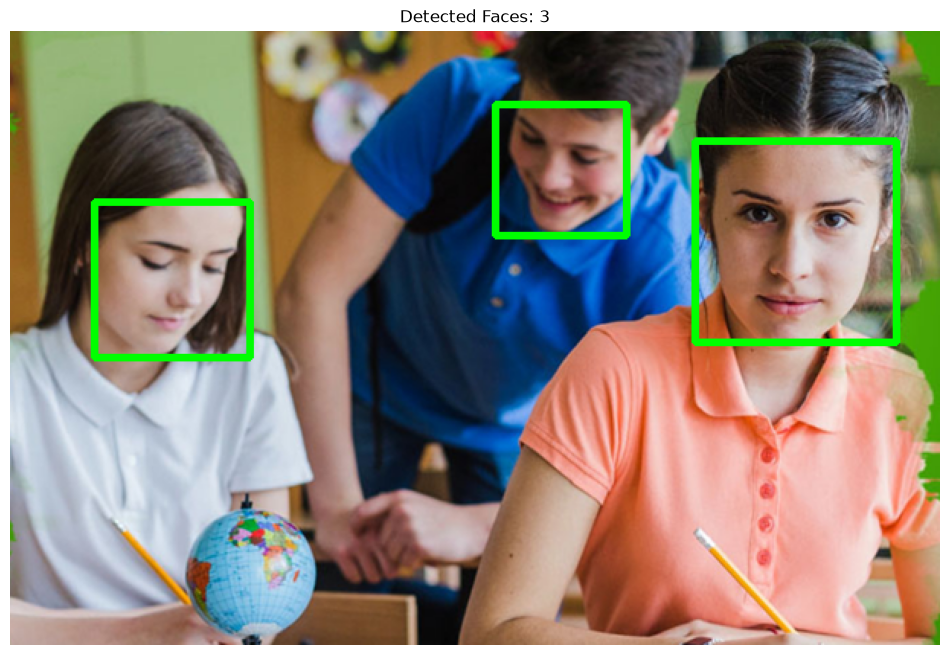

Number of faces detected: 3


In [6]:

# Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Detect faces
faces = face_detector.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

# Draw rectangles around detected faces
result = image_rgb.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        3
    )

# Display result
plt.figure(figsize=(12, 8))
plt.imshow(result)
plt.title(f"Detected Faces: {len(faces)}")
plt.axis("off")
plt.show()

print("Number of faces detected:", len(faces))


In [7]:
import cv2
import matplotlib.pyplot as plt

cascade_path = (
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

face_detector = cv2.CascadeClassifier(cascade_path)

if face_detector.empty():
    raise RuntimeError("Face detection model failed!")

print("Face Detection Model Loaded!")

Face Detection Model Loaded!


In [8]:
# Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Detect faces
faces = face_detector.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

print("Number of detected faces:", len(faces))

Number of detected faces: 3


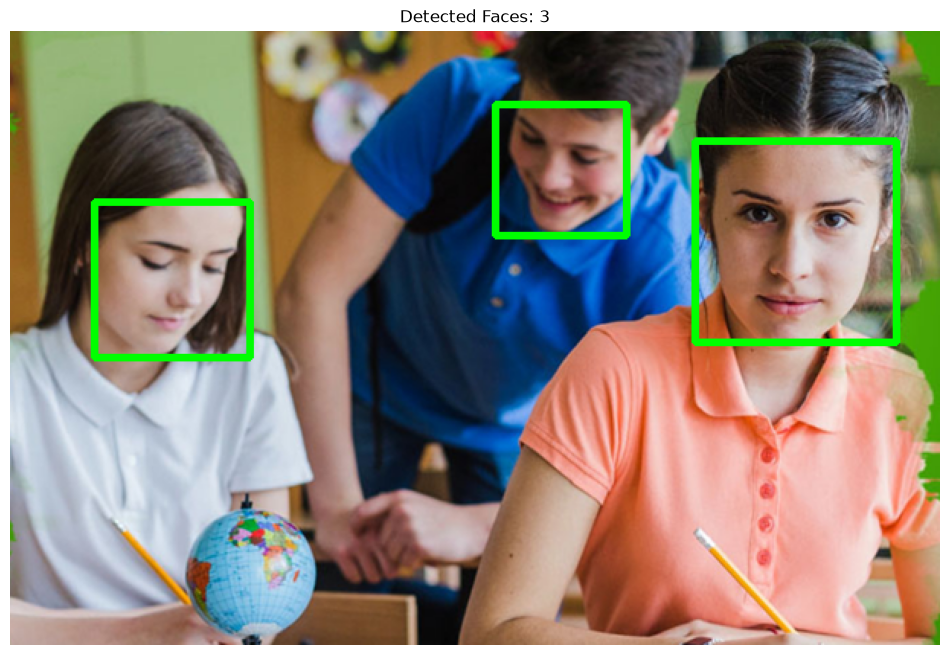

In [9]:
# Copy original image
result = image.copy()

# Draw rectangle around each detected face
for (x, y, w, h) in faces:

    cv2.rectangle(
        result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        3
    )

# Convert BGR to RGB
result_rgb = cv2.cvtColor(
    result,
    cv2.COLOR_BGR2RGB
)

# Display result
plt.figure(figsize=(12, 8))
plt.imshow(result_rgb)
plt.title(f"Detected Faces: {len(faces)}")
plt.axis("off")
plt.show()

In [10]:
faces = face_detector.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=8,
    minSize=(50, 50)
)

print("Detected:", len(faces))

Detected: 2


In [11]:
import cv2
import time

print("OpenCV:", cv2.__version__)
print("Webcam module ready!")

OpenCV: 4.13.0
Webcam module ready!


In [12]:
cascade_path = (
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

face_detector = cv2.CascadeClassifier(cascade_path)

if face_detector.empty():
    raise RuntimeError("Face detection model not loaded!")

print("Face Detection Model: READY")

Face Detection Model: READY


In [13]:
camera = cv2.VideoCapture(0)

if not camera.isOpened():
    raise RuntimeError(
        "Cannot access webcam. Check camera connection and permissions."
    )

print("Webcam connected successfully!")

Webcam connected successfully!


In [14]:
frame_count = 0
start_time = time.time()

try:
    while True:

        # Read frame from webcam
        success, frame = camera.read()

        if not success:
            print("Cannot read webcam frame!")
            break

        # Convert frame to grayscale
        gray = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2GRAY
        )

        # Detect faces
        faces = face_detector.detectMultiScale(
            gray,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(40, 40)
        )

        # Draw rectangle around detected faces
        for (x, y, w, h) in faces:

            cv2.rectangle(
                frame,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

            cv2.putText(
                frame,
                "Face Detected",
                (x, y - 10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (0, 255, 0),
                2
            )

        # Calculate FPS
        frame_count += 1
        elapsed = time.time() - start_time
        fps = frame_count / elapsed if elapsed > 0 else 0

        # Display information
        cv2.putText(
            frame,
            f"Faces: {len(faces)} | FPS: {fps:.1f}",
            (10, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 0, 255),
            2
        )

        # Show webcam
        cv2.imshow(
            "Real-Time Face Detection",
            frame
        )

        # Press Q to exit
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    camera.release()
    cv2.destroyAllWindows()

print("Webcam stopped!")

Webcam stopped!
